# 第6回　Ridge と Lasso — 係数を縮めることで過学習を抑える

| 項目 | 内容 |
| --- | --- |
| 教科書の範囲 | 第 5 章 正則化　5.1 Ridge / 5.2 劣微分 / 5.3 Lasso / 5.4 Ridge と Lasso を比較して / 5.5 $\lambda$ の値の設定 |
| 図・例 | 図 5.1〜5.8、例 48〜51 |
| 章末問題 | 問題 49 〜 問題 56 |
| この回の到達点 | ① $\lambda>0$ なら $X^TX+N\lambda I$ が必ず正則であることを示せる<br>② $|x|$ の $x=0$ での劣微分が $[-1,1]$ であることを定義から示せる<br>③ ソフト閾値作用素を導き、座標降下法で Lasso を実装できる |

第 5 回の AIC は「変数を使うか使わないか」という $2^p$ 通りの離散的な探索だった。
この回では、係数の大きさに**<font color="#E8710A">連続的な罰則</font>**を課す。
$L_2$ ノルムの二乗を罰すれば Ridge、$L_1$ ノルムを罰すれば Lasso になり、
Lasso では**<font color="#E8710A">罰則を強めると係数がちょうど 0 になる</font>**ため、変数選択が自動的に実現される。

---

**<font color="#E8710A">［要点］2 つの罰則</font>**

$$L_{\text{Ridge}}=\frac{1}{N}\|y-X\beta\|^2+\lambda\|\beta\|_2^2,\qquad
L_{\text{Lasso}}=\frac{1}{2N}\|y-X\beta\|^2+\lambda\|\beta\|_1$$
ここでは二乗誤差の係数も異なる規約を使っている。数値的に同じλが同じ罰則の強さを意味するわけではない。$\|\beta\|_2^2=\sum_j\beta_j^2$ は原点でなめらか、
$\|\beta\|_1=\sum_j|\beta_j|$ は原点で**とがっている**。
このとがりが「係数がちょうど 0 になる」現象を生む。

**以下では一般性を失わず切片を 0 とし（中心化して消す）、傾きだけを正則化の対象とする。**

---

[学習記録の概要・検証結果・掲載時の修正](../README.md)


## 0. インポートと初期設定

In [1]:
#使うライブラリをまとめて読み込む
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

#環境にある日本語フォントを選ぶ（OSのパッケージは自動インストールしない）
from matplotlib import font_manager
font_candidates = ['Noto Sans CJK JP', 'Noto Sans JP', 'IPAexGothic', 'IPAPGothic',
                   'IPAGothic', 'Hiragino Sans', 'Yu Gothic', 'Meiryo']
installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = [name for name in font_candidates if name in installed_fonts] + ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

#グラフの見た目をそろえる
plt.rcParams['figure.figsize'] = (7.2, 4.4)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

#色設定
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
MAGENTA, GREEN, VIOLET, RED = '#e87ba4', '#008300', '#4a3aa7', '#e34948'
PAL = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=PAL)

#乱数。教科書の randn(n) と同じ書き方ができるようにしておく
rng = np.random.default_rng(2026)
def randn(*shape):
    return rng.standard_normal(shape)

In [2]:
#元Notebookと同じBoston住宅価格CSV。データの版をコミットで固定する。
import os
DATA_URL = 'https://raw.githubusercontent.com/selva86/datasets/5d788b9286864a80bc7b23703f372823bf6c600e/BostonHousing.csv'

def load_boston(csv_path=None):
    """csv_pathまたはBOSTON_CSV_PATHがあればローカルCSV、それ以外は公開CSVを読む。"""
    location = csv_path if csv_path is not None else os.environ.get('BOSTON_CSV_PATH', DATA_URL)
    df = pd.read_csv(location)
    expected = ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis',
                'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']
    if list(df.columns) != expected or df.shape != (506, 14) or df.isna().any().any():
        raise ValueError('想定したBostonHousing.csvの列・行数・欠損状態と異なります。')
    boston = type('Bunch', (), {})()
    boston.data = df.iloc[:, :13].to_numpy()
    boston.target = df['medv'].to_numpy()
    boston.feature_names = np.array([name.upper() for name in expected[:-1]])
    return boston


---
## 1. Ridge（教科書 5.1）

### 1.1 なぜ正則化が必要か

第 2 回で $\hat\beta=(X^TX)^{-1}X^Ty$ を導いたとき、$X^TX$ が正則であることを仮定した。
しかし $p$ が $N$ に近い、あるいは説明変数どうしが似ている（共線形性）と、
$X^TX$ の小さい固有値に対応する方向で推定が不安定になることがある。行列式の大小は尺度に依存するため、
不安定性は固有値・特異値や条件数も見て判断する。誤差が等分散・無相関という仮定のもとでは

$$V[\hat\beta]=\sigma^2(X^TX)^{-1}$$

の対角成分が大きくなり、信頼区間が広がって推定が使いものにならなくなる。

### 1.2 目的関数と解

$\lambda\ge0$ を定数として

$$L=\frac{1}{N}\|y-X\beta\|^2+\lambda\|\beta\|_2^2\tag{5.1}$$

を $\beta$ で微分すると

$$0=-\frac{2}{N}X^T(y-X\beta)+2\lambda\beta
\;\Longrightarrow\;
(X^TX+N\lambda I)\beta=X^Ty$$

$X^TX+N\lambda I$ が正則であれば

$$\hat\beta=(X^TX+N\lambda I)^{-1}X^Ty$$

### 1.3 $\lambda>0$ なら必ず正則になる

第 1 回の命題を 3 つ重ねると示せる。

1. $X^TX$ は $B=X$ とおいた $B^TB$ の形なので、命題 10 より非負定値。固有値はすべて $\ge0$。

2. $S$ の固有値が $\mu$ なら $S+cI$ の固有値は $\mu+c$。よって $X^TX+N\lambda I$ の固有値は $\mu_j+N\lambda>0$。

3. すべての固有値が正なら $\det=\prod_j(\mu_j+N\lambda)>0$。命題 1 より正則。

$X^TX$ の固有値を $\mu_1,\dots,\mu_p\ (\ge0)$ とすると
$X^TX+N\lambda I$ の固有値は $\mu_1+N\lambda,\dots,\mu_p+N\lambda$ である
（固有ベクトルは共通で、$Sv=\mu v\Rightarrow(S+cI)v=(\mu+c)v$）。
$\lambda>0$ ならすべて正なので $\det>0$、よって正則。

---

**<font color="#E8710A">［要点］$\lambda=0$ との違い</font>**

$\lambda=0$ のときは $X^TX$ が正則でない場合がある。とくに $N<p$ では命題 3 より
$\operatorname{rank}(X^TX)\le N<p$ なので**必ず**正則でない。

$\lambda>0$ を足すだけで、$N<p$ であっても解が一意に定まる。
これが正則化の第一の効能である（問題 49）。

---

### 1.4 固有値による説明

$X^TX=V\Lambda V^T$（命題 9）と対角化すると

$$\hat\beta_{\text{Ridge}}=V(\Lambda+N\lambda I)^{-1}V^TX^Ty$$

最小二乗解と比べると、第 $j$ 主軸方向の成分が $\dfrac{\mu_j}{\mu_j+N\lambda}$ 倍に縮む。
**<font color="#E8710A">$\mu_j$ が小さい方向（データがあまり広がっていない方向）ほど強く縮む</font>**。
不安定な方向を重点的に抑える、という設計になっている。

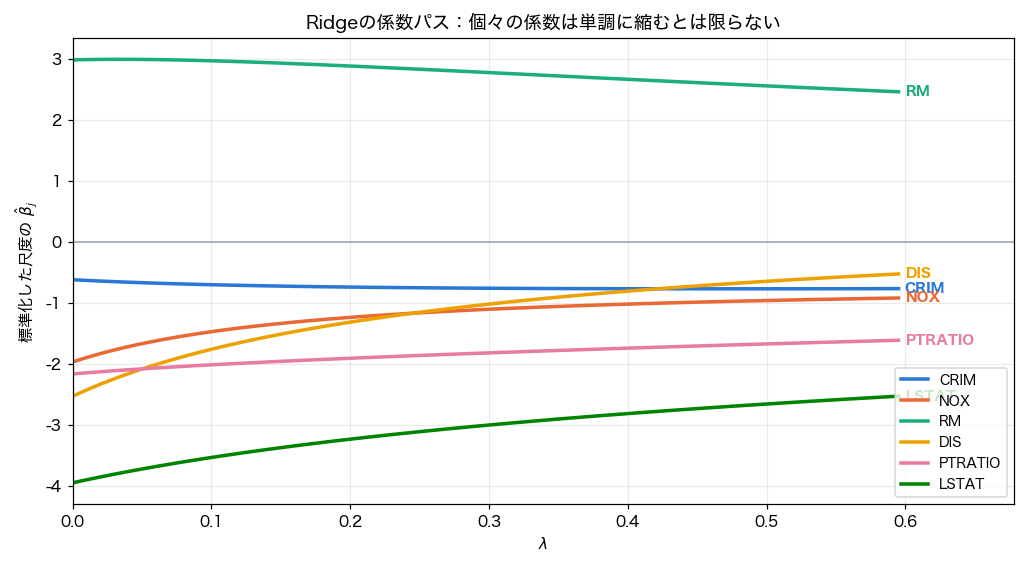

標準化した尺度での係数
変数                λ=0（最小二乗）      λ=0.05       λ=0.5
CRIM               -0.61890    -0.66802    -0.76821
NOX                -1.96874    -1.66779    -0.96033
RM                  2.98455     2.99188     2.55842
DIS                -2.53139    -2.08396    -0.64552
PTRATIO            -2.16454    -2.08115    -1.67210
LSTAT              -3.94890    -3.72253    -2.65680

λ→∞で係数は0へ向かうが、有限範囲では各係数の絶対値は単調とは限らない。Ridgeには係数を一律に厳密な0へ切り落とす仕組みはない。


In [3]:
def ridge(X, y, lam=0):
    """教科書 p.110 の ridge。中心化・標準化してから Ridge 解を返す"""
    X = np.asarray(X, float).copy()
    n, p = X.shape
    if lam < 0:
        raise ValueError("lam must be nonnegative")
    X_bar = X.mean(axis=0)
    s = X.std(axis=0)                              # ddof=0の標準偏差で標準化
    if np.any(s == 0):
        raise ValueError("定数列は除いてください")
    X = (X - X_bar) / s
    y_bar = y.mean()
    yc = y - y_bar
    beta = np.linalg.solve(X.T @ X + n*lam*np.eye(p), X.T @ yc)
    beta = beta / s                                # 元の尺度に戻す
    beta_0 = y_bar - X_bar @ beta
    return {"beta": beta, "beta_0": beta_0}

boston = load_boston()
pick = [0, 4, 5, 7, 10, 12]                        # CRIM, NOX, RM, DIS, PTRATIO, LSTAT
Xb, yb = boston.data[:, pick], boston.target
labels = [str(name) for name in boston.feature_names[pick]]

lam_seq = np.arange(0, 0.6, 0.005)
sd = Xb.std(axis=0)
#図では標準化した尺度の係数 β·s を描く（元の単位のままでは桁がそろわない）
paths = np.array([ridge(Xb, yb, l)["beta"] * sd for l in lam_seq])

fig, ax = plt.subplots(figsize=(9.4, 5.2))
for j, (lab, c) in enumerate(zip(labels, PAL)):
    ax.plot(lam_seq, paths[:, j], color=c, lw=2.3, label=lab)
    ax.annotate(lab, xy=(lam_seq[-1], paths[-1, j]), xytext=(4, 0),
                textcoords="offset points", color=c, fontsize=9, fontweight="bold",
                va="center")
ax.axhline(0, c="#98a4b0", lw=1.0)
ax.set_xlim(0, lam_seq[-1]*1.14)
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"標準化した尺度の $\hat\beta_j$")
ax.set_title("Ridgeの係数パス：個々の係数は単調に縮むとは限らない")
ax.legend(fontsize=9, loc="lower right"); plt.tight_layout(); plt.show()

print("標準化した尺度での係数")
print(f"{'変数':<9}{'λ=0（最小二乗）':>18}{'λ=0.05':>12}{'λ=0.5':>12}")
for j, lab in enumerate(labels):
    print(f"{lab:<9}{paths[0,j]:18.5f}{ridge(Xb,yb,0.05)['beta'][j]*sd[j]:12.5f}"
          f"{ridge(Xb,yb,0.5)['beta'][j]*sd[j]:12.5f}")
print("\nλ→∞で係数は0へ向かうが、有限範囲では各係数の絶対値は単調とは限らない。Ridgeには係数を一律に厳密な0へ切り落とす仕組みはない。")

| 書き方 | していること | 読みどころ |
| --- | --- | --- |
| `X = (X - X_bar) / s` | 標準化 | 罰則 $\lambda\Vert \beta\Vert ^2$ は係数の**尺度に依存する**。説明変数をメートルからセンチに変えると係数は1/100になり、罰則の効き方が変わってしまう。必ず標準化してから正則化する |
| `y - y_bar` | 中心化 | 切片を罰則の対象から外すための操作。中心化すると切片は 0 になる（第 2 回 (1.6)） |
| `X.T @ X + n*lam*np.eye(p)` | $X^TX+N\lambda I$ | 教科書の (5.1) は $\frac1N\Vert y-X\beta\Vert ^2$ と割っているので $N\lambda$ が出る。$\frac1N$ を付けない流儀では単に $\lambda I$ になる。文献ごとに確認すること |
| `beta = beta / s` | 尺度を戻す | 標準化した空間で得た係数を元の単位に戻す。ここを忘れると予測がまったく合わない |
| `beta_0 = y_bar - X_bar @ beta` | 切片の復元 | 第 2 回の $\hat\beta_0=\bar y-\hat\beta_1\bar x$ の多変数版 |

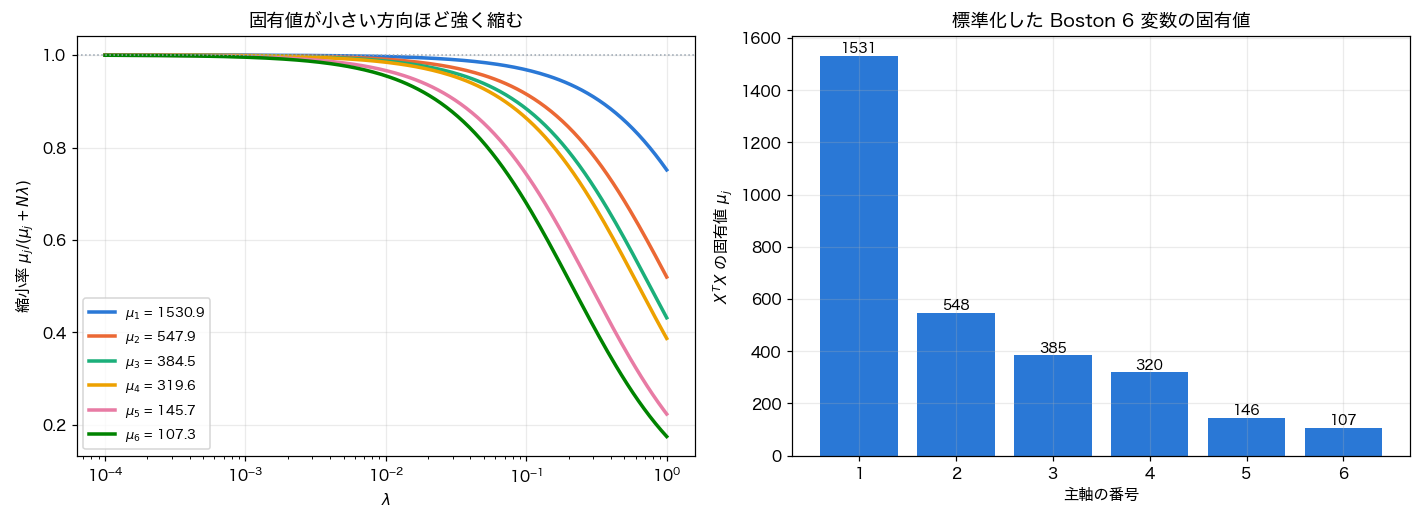

条件数 μ_max / μ_min = 14.27
この比が大きいほど最小二乗解は不安定で、Ridge の効果が大きい。


In [4]:
#固有値による説明：小さい固有値の方向ほど強く縮む
Xs = (Xb - Xb.mean(0)) / Xb.std(0)
n_, p_ = Xs.shape
mu, V = np.linalg.eigh(Xs.T @ Xs)
order = np.argsort(mu)[::-1]; mu = mu[order]; V = V[:, order]

lam_grid = np.geomspace(1e-4, 1.0, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.0, 4.8))
for j, c in zip(range(p_), PAL):
    a1.semilogx(lam_grid, mu[j]/(mu[j] + n_*lam_grid), color=c, lw=2.3,
                label=rf"$\mu_{{{j+1}}}$ = {mu[j]:.1f}")
a1.axhline(1, c="#98a4b0", lw=1.0, ls=":")
a1.set_xlabel(r"$\lambda$"); a1.set_ylabel(r"縮小率 $\mu_j/(\mu_j+N\lambda)$")
a1.set_title("固有値が小さい方向ほど強く縮む"); a1.legend(fontsize=8.5)

a2.bar(np.arange(1, p_+1), mu, color=BLUE)
a2.set_xlabel("主軸の番号"); a2.set_ylabel(r"$X^TX$ の固有値 $\mu_j$")
a2.set_title("標準化した Boston 6 変数の固有値")
for j, v in enumerate(mu):
    a2.text(j+1, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout(); plt.show()

print("条件数 μ_max / μ_min =", round(mu[0]/mu[-1], 2))
print("この比が大きいほど最小二乗解は不安定で、Ridge の効果が大きい。")

---
## 2. 劣微分 — 微分できない点をどう扱うか（教科書 5.2）

### 2.1 凸関数の定義

任意の $0<\alpha<1$ と $x,y\in\mathbb{R}$ について

$$f(\alpha x+(1-\alpha)y)\le\alpha f(x)+(1-\alpha)f(y)$$

が成り立つとき、$f$ は（下に）**<font color="#E8710A">凸</font>**であるという。
$f(x)=|x|$ は凸である。実際 $|\alpha x+(1-\alpha)y|\le\alpha|x|+(1-\alpha)|y|$ は三角不等式そのもの。

### 2.2 劣微分の定義

凸関数 $f$ と $x_0\in\mathbb{R}$ について、任意の $x\in\mathbb{R}$ で

$$f(x)\ge f(x_0)+z(x-x_0)\tag{5.2}$$

を満たす $z$ の集合を $f$ の $x_0$ における**<font color="#E8710A">劣微分</font>**という。
グラフの下に引ける直線の傾きを全部集めたもの、と読める。

$f$ が $x_0$ で微分可能なら、劣微分は $\{f'(x_0)\}$ という 1 要素の集合になる。
証明の要点は次のとおり。凸性より $\alpha\{f(x)-f(x_0)\}\ge f(x_0+\alpha(x-x_0))-f(x_0)$ なので

$$f(x)-f(x_0)\ge\frac{f(x_0+\alpha(x-x_0))-f(x_0)}{\alpha(x-x_0)}(x-x_0)$$

$\alpha\to0$ で右辺の係数は $f'(x_0)$ に近づく。逆に $z\neq f'(x_0)$ が (5.2) を満たすと、
$x>x_0$ からは $\dfrac{f(x)-f(x_0)}{x-x_0}\ge z$、$x<x_0$ からは $\le z$ が必要になり、
両側微分係数が一致することから $z=f'(x_0)$。

### 2.3 $|x|$ の $x=0$ における劣微分

---

**<font color="#C08A00">［命題］$f(x)=|x|$ の $x=0$ での劣微分（教科書 p.113）</font>**

$$\text{任意の }x\in\mathbb{R}\text{ で }|x|\ge zx \iff -1\le z\le1$$
**（$\Rightarrow$）** $x>0$ で成立するには $z\le1$、$x<0$ で成立するには $z\ge-1$ が必要。

**（$\Leftarrow$）** $-1\le z\le1$ なら $zx\le|z||x|\le|x|$ が任意の $x$ で成立。

したがって $|x|$ の $x=0$ における劣微分は $[-1,1]$ である。

---

この $[-1,1]$ という**<font color="#E8710A">区間</font>**が、Lasso のすべての性質の源である。

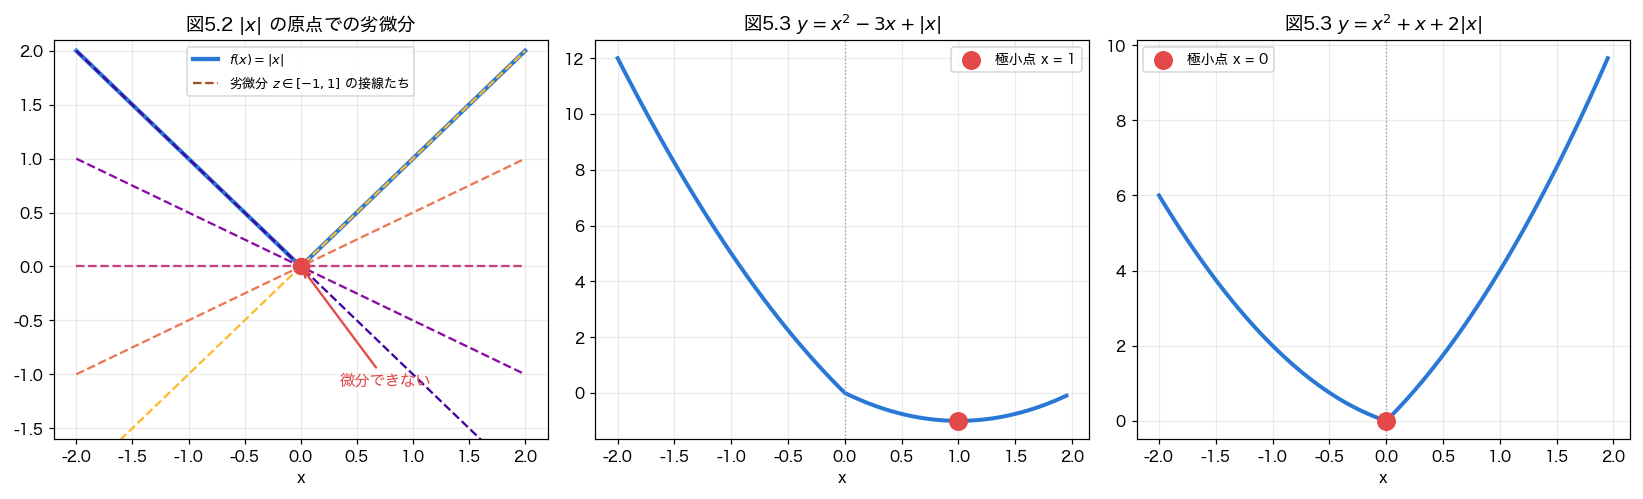

左の f(x)=x²-3x+|x| は x>0 で f'=2x-2 なので x=1 で極小。x=0 の劣微分は
   2·0-3+[-1,1] = [-4,-2] で 0 を含まないので x=0 は極小でない。
右の f(x)=x²+x+2|x| は x=0 の劣微分が 0+1+2[-1,1] = [-1,3] ∋ 0 なので x=0 で極小。
→ 微分できなくても、劣微分が 0 を含むかどうかで極小を判定できる。


In [5]:
#図5.2・図5.3 に色を足したもの
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.6))

#左：|x| は原点で微分できない
xg = np.linspace(-2, 2, 400)
axes[0].plot(xg, np.abs(xg), c=BLUE, lw=2.8, label="$f(x)=|x|$")
for z, c in zip([-1, -0.5, 0, 0.5, 1], plt.cm.plasma(np.linspace(0.1, 0.85, 5))):
    axes[0].plot(xg, z*xg, color=c, lw=1.5, ls="--")
axes[0].plot([], [], color="#a0522d", lw=1.5, ls="--",
             label=r"劣微分 $z\in[-1,1]$ の接線たち")
axes[0].scatter([0], [0], s=110, c=RED, zorder=5)
axes[0].annotate("微分できない", xy=(0, 0), xytext=(0.35, -1.1), color=RED,
                 fontsize=10, arrowprops=dict(arrowstyle="->", color=RED, lw=1.5))
axes[0].set_ylim(-1.6, 2.1); axes[0].set_title("図5.2 $|x|$ の原点での劣微分")
axes[0].legend(fontsize=8.5); axes[0].set_xlabel("x")

#中・右：例49
x_seq = np.arange(-2, 2, 0.05)
for ax, expr, ttl, star in [
        (axes[1], x_seq**2 - 3*x_seq + np.abs(x_seq), r"$y=x^2-3x+|x|$", (1., -1.)),
        (axes[2], x_seq**2 + x_seq + 2*np.abs(x_seq), r"$y=x^2+x+2|x|$", (0., 0.))]:
    ax.plot(x_seq, expr, c=BLUE, lw=2.6)
    ax.scatter(*star, s=130, c=RED, zorder=5,
               label=f"極小点 x = {star[0]:.0f}")
    ax.axvline(0, c="#98a4b0", lw=0.9, ls=":")
    ax.set_title(f"図5.3 {ttl}"); ax.set_xlabel("x"); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

print("左の f(x)=x²-3x+|x| は x>0 で f'=2x-2 なので x=1 で極小。x=0 の劣微分は")
print("   2·0-3+[-1,1] = [-4,-2] で 0 を含まないので x=0 は極小でない。")
print("右の f(x)=x²+x+2|x| は x=0 の劣微分が 0+1+2[-1,1] = [-1,3] ∋ 0 なので x=0 で極小。")
print("→ 微分できなくても、劣微分が 0 を含むかどうかで極小を判定できる。")

---
## 3. Lasso（教科書 5.3）

### 3.1 目的関数

$$L=\frac{1}{2N}\|y-X\beta\|^2+\lambda\|\beta\|_1\tag{5.3}$$

第 1 項を 2 で割っているのは、あとの式を簡単にするためで本質的ではない。

### 3.2 直交する場合 — ソフト閾値作用素

まず変数が直交している場合、すなわち

$$\frac1N\sum_{i=1}^{N}x_{i,j}x_{i,k}=\begin{cases}1&j=k\\0&j\neq k\end{cases}\tag{5.4}$$

を仮定する。$s_j:=\dfrac1N\sum_{i=1}^{N}x_{i,j}y_i$ とおくと、$L$ の $\beta_j$ に関する劣微分は

$$0\in-s_j+\beta_j+\lambda\begin{cases}
1,&\beta_j>0\\ -1,&\beta_j<0\\ [-1,1],&\beta_j=0
\end{cases}\tag{5.5}$$

場合分けして解くと

$$\beta_j=\begin{cases}
s_j-\lambda,& s_j>\lambda\\
s_j+\lambda,& s_j<-\lambda\\
0,& -\lambda\le s_j\le\lambda
\end{cases}
=\mathcal{S}_\lambda(s_j)$$

この $\mathcal{S}_\lambda$ を**<font color="#E8710A">ソフト閾値作用素</font>**という。

---

**<font color="#E8710A">［要点］ソフト閾値と「ハード閾値」の違い</font>**

$\mathcal{S}_\lambda(s)$ は $|s|\le\lambda$ で**ちょうど 0**、それ以外では $\lambda$ だけ原点方向へずらす。
$|s|$ が大きい係数も一律に $\lambda$ だけ縮むので、**推定値には $\lambda$ 分の偏りが残る**。

これを嫌って「$|s|>\lambda$ ならそのまま、そうでなければ 0」とするのがハード閾値だが、
対応するL0型の最適化は一般に非凸となる。なおLassoも、特徴量が従属する場合などには係数の解が一意とは限らない。

Lasso が広く使われるのは、**変数選択と凸最適化を両立している**点にある。

---

### 3.3 直交しない場合 — 座標降下法

(5.4) が成り立たない一般の場合には、係数ごとに独立なソフト閾値の式だけでは解けない。そこで
**<font color="#E8710A">$\beta_k\ (k\neq j)$ を固定して $\beta_j$ だけを更新する</font>**操作を、$j=1,\dots,p$ と順に回し、
収束するまで繰り返す。

$r_{i,j}:=y_i-\sum_{k\neq j}x_{i,k}\beta_k$（$j$ 以外で説明しきれなかった残り）とおくと

$$0\in-\frac1N\sum_{i=1}^{N}x_{i,j}(r_{i,j}-x_{i,j}\beta_j)+\lambda\,\partial|\beta_j|$$

$\frac1N\sum_i x_{i,j}^2=1$（標準化済み）を使えば、$s_j=\frac1N\sum_i r_{i,j}x_{i,j}$ として

$$\beta_j\leftarrow\mathcal{S}_\lambda(s_j)$$

**<font color="#E8710A">1 変数ずつなら、直交の場合とまったく同じ式で更新できる</font>**。これが座標降下法である。

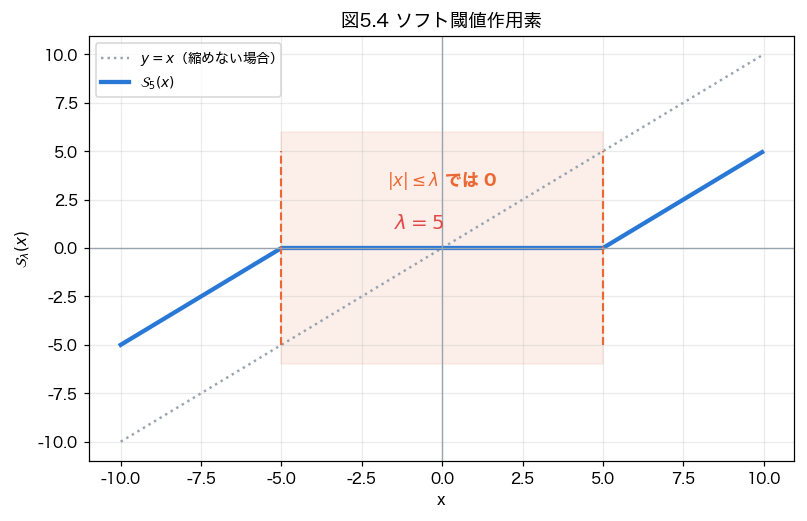

  S_5( -8.0) =  -3.00
  S_5( -5.0) =  -0.00
  S_5( -2.0) =  -0.00
  S_5(  0.0) =   0.00
  S_5(  3.0) =   0.00
  S_5(  5.0) =   0.00
  S_5(  9.0) =   4.00


In [6]:
def soft_th(lam, x):
    """ソフト閾値作用素 S_λ(x)（教科書 p.115）"""
    if lam < 0:
        raise ValueError("lam must be nonnegative")
    return np.sign(x) * np.maximum(np.abs(x) - lam, 0)

fig, ax = plt.subplots(figsize=(7.4, 4.8))
x_seq = np.arange(-10, 10, 0.05)
ax.plot(x_seq, x_seq, c="#98a4b0", lw=1.6, ls=":", label="$y=x$（縮めない場合）")
ax.plot(x_seq, soft_th(5, x_seq), c=BLUE, lw=2.8, label=r"$\mathcal{S}_5(x)$")
ax.plot([-5, -5], [-5, 5], c=ORANGE, ls="--", lw=1.4)
ax.plot([5, 5], [-5, 5], c=ORANGE, ls="--", lw=1.4)
ax.fill_between([-5, 5], -6, 6, color=ORANGE, alpha=0.10)
ax.text(0, 3.2, r"$|x|\leq\lambda$ では 0", ha="center", color=ORANGE,
        fontsize=11, fontweight="bold")
ax.text(-1.5, 1.0, r"$\lambda=5$", fontsize=13, color=RED)
ax.axhline(0, c="#98a4b0", lw=0.9); ax.axvline(0, c="#98a4b0", lw=0.9)
ax.set_xlabel("x"); ax.set_ylabel(r"$\mathcal{S}_\lambda(x)$")
ax.set_title("図5.4 ソフト閾値作用素"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

for v in [-8., -5., -2., 0., 3., 5., 9.]:
    print(f"  S_5({v:5.1f}) = {soft_th(5, v):6.2f}")

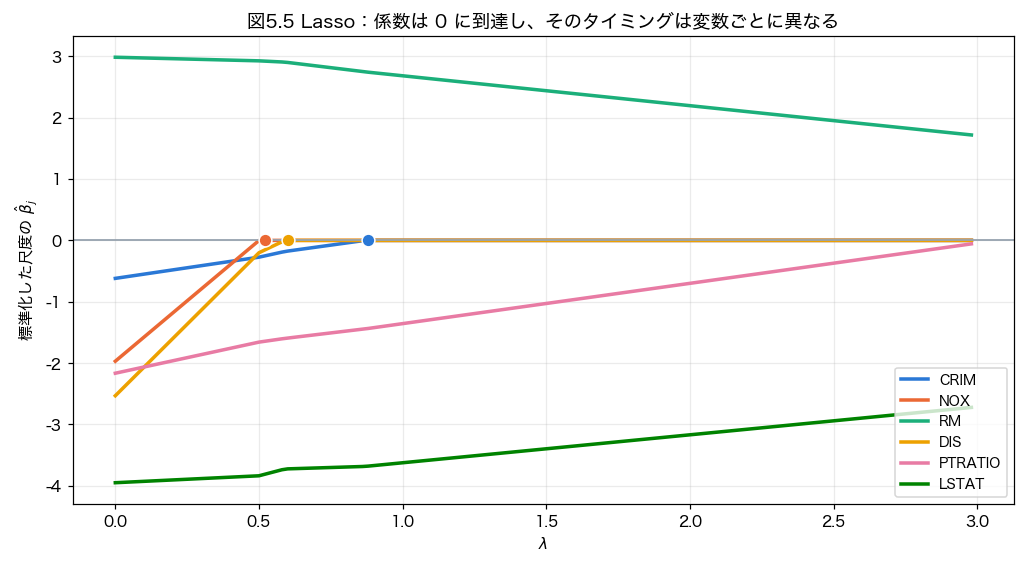

標準化した尺度での係数
変数               λ=0      λ=0.5      λ=1.5     0 になる λ
CRIM        -0.61890   -0.27346   -0.00000        0.88
NOX         -1.96875   -0.00217   -0.00000        0.52
RM           2.98455    2.92587    2.43894           —
DIS         -2.53139   -0.20149   -0.00000        0.60
PTRATIO     -2.16454   -1.65773   -1.02825           —
LSTAT       -3.94889   -3.83593   -3.39600           —

sklearn の Lasso（標準化後、alpha=0.5）: [-2.73460e-01 -2.16000e-03  2.92587e+00 -2.01470e-01 -1.65773e+00
 -3.83593e+00]
自作（標準化後の尺度に直したもの）      : [-2.73460e-01 -2.17000e-03  2.92587e+00 -2.01490e-01 -1.65773e+00
 -3.83593e+00]


In [7]:
def lasso(X, y, lam=0, tol=1e-5, max_iter=500):
    """座標降下法による Lasso（教科書 p.116 の lasso）"""
    X = np.asarray(X, float).copy()
    n, p = X.shape
    if lam < 0:
        raise ValueError("lam must be nonnegative")
    X_bar = X.mean(axis=0); s = X.std(axis=0)
    if np.any(s == 0):
        raise ValueError("定数列は除いてください")
    X = (X - X_bar) / s                         # 標準化（1/n Σx² = 1 にする）
    y_bar = y.mean(); yc = y - y_bar
    beta = np.zeros(p); beta_old = np.ones(p)
    it = 0
    while np.max(np.abs(beta - beta_old)) > tol and it < max_iter:
        beta_old = beta.copy()
        for j in range(p):
            idx = [k for k in range(p) if k != j]
            r = yc - X[:, idx] @ beta[idx]      # j 以外で説明しきれなかった残り
            beta[j] = soft_th(lam, X[:, j] @ r / n)
        it += 1
    converged = bool(np.max(np.abs(beta - beta_old)) <= tol)
    beta = beta / s
    return {"beta": beta, "beta_0": y_bar - X_bar @ beta, "iter": it, "converged": converged}

lam_seq = np.arange(0, 3.0, 0.02)
paths_l = np.array([lasso(Xb, yb, l)["beta"] * sd for l in lam_seq])

fig, ax = plt.subplots(figsize=(9.4, 5.2))
for j, (lab, c) in enumerate(zip(labels, PAL)):
    ax.plot(lam_seq, paths_l[:, j], color=c, lw=2.3, label=lab)
    first0 = lam_seq[np.argmax(np.isclose(paths_l[:, j], 0))] \
        if np.any(np.isclose(paths_l[:, j], 0)) else None
    if first0 is not None and first0 > 0:
        ax.scatter([first0], [0], s=70, color=c, zorder=5, edgecolor="white")
ax.axhline(0, c="#98a4b0", lw=1.2)
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"標準化した尺度の $\hat\beta_j$")
ax.set_title("図5.5 Lasso：係数は 0 に到達し、そのタイミングは変数ごとに異なる")
ax.legend(fontsize=9, loc="lower right"); plt.tight_layout(); plt.show()

print("標準化した尺度での係数")
print(f"{'変数':<9}{'λ=0':>11}{'λ=0.5':>11}{'λ=1.5':>11}{'0 になる λ':>12}")
for j, lab in enumerate(labels):
    nz = lam_seq[np.isclose(paths_l[:, j], 0)]
    first = f"{nz[0]:.2f}" if len(nz) else "—"
    print(f"{lab:<9}{paths_l[0,j]:11.5f}{lasso(Xb,yb,0.5)['beta'][j]*sd[j]:11.5f}"
          f"{lasso(Xb,yb,1.5)['beta'][j]*sd[j]:11.5f}{first:>12}")

from sklearn.linear_model import Lasso
Xstd = (Xb - Xb.mean(0)) / Xb.std(0)
sk = Lasso(alpha=0.5, tol=1e-10, max_iter=50000).fit(Xstd, yb)
print("\nsklearn の Lasso（標準化後、alpha=0.5）:", np.round(sk.coef_, 5))
print("自作（標準化後の尺度に直したもの）      :",
      np.round(lasso(Xb, yb, 0.5)["beta"] * Xb.std(0), 5))

| 書き方 | していること | 読みどころ |
| --- | --- | --- |
| `while np.max(np.abs(beta - beta_old)) > tol` | 収束判定 | 1 巡回したあとの係数の変化が十分小さくなったら止める。`max_iter` を付けておかないと、収束しない設定で無限ループになる |
| `idx = [k for k in range(p) if k != j]` | $k\neq j$ | 教科書の `list(set(range(p))-{j})` と同じ。順序が保たれるぶんこちらが安全 |
| `r = yc - X[:, idx] @ beta[idx]` | $r_{i,j}$ | $j$ 番目の変数**以外**で説明した残り。ここに $j$ 番目を含めてしまうのが最も多い誤り |
| `X[:, j] @ r / n` | $s_j$ | 標準化してあるので $\frac1N\sum_i x_{i,j}^2=1$。この 1 のおかげで更新式が $\mathcal{S}_\lambda(s_j)$ だけになる |
| `beta[j] = soft_th(lam, ...)` | その場で書き換える | 更新した値をすぐ次の $j$ の計算に使う（Gauss–Seidel 型）。一括更新（Jacobi 型）は別の反復法であり、同じ更新式をそのまま並列化しても収束が保証されるわけではない |
| `Lasso(alpha=0.5)` | sklearn との対応 | sklearn の `alpha` が教科書の $\lambda$ に対応する。目的関数の $\frac{1}{2N}$ の付け方が同じなので値がそのまま一致する |

---
## 4. Ridge と Lasso を比較して（教科書 5.4）

### 4.1 制約つき最適化として見る

$p=2$ とし、最小二乗解を $(\hat\beta_1,\hat\beta_2)$ とする。
$\sum_i x_{i,1}(y_i-\hat y_i)=\sum_i x_{i,2}(y_i-\hat y_i)=0$（第 2 回の直交性）を使うと、
残差二乗和は

$$S=(\beta_1-\hat\beta_1)^2\sum_i x_{i,1}^2
+2(\beta_1-\hat\beta_1)(\beta_2-\hat\beta_2)\sum_i x_{i,1}x_{i,2}
+(\beta_2-\hat\beta_2)^2\sum_i x_{i,2}^2+RSS\tag{5.6}$$

となり、$(\hat\beta_1,\hat\beta_2)$ を中心とする**<font color="#E8710A">楕円の等高線</font>**をもつ。

Ridge と Lasso は、それぞれ

$$\beta_1^2+\beta_2^2\le C\quad\text{（円）},\qquad
|\beta_1|+|\beta_2|\le C'\quad\text{（ひし形）}$$

という制約のもとで (5.6) を最小にする問題と等価である。

### 4.2 なぜ Lasso だけが 0 を出すのか

楕円の等高線を中心から広げていき、最初に制約領域に触れた点が解になる。

1. ひし形には 4 つの**とがった頂点**があり、そこは軸上（$\beta_1=0$ または $\beta_2=0$）にある。

2. 楕円がなめらかな曲線に触れるとき、接点はどこにでもありうる。しかし頂点は「向きの集合」をもつので、幅広い傾きの楕円が頂点で接する。

3. $C'$ が小さい（$\lambda$ が大きい）ほどひし形は小さくなり、頂点で接する確率が上がる。

4. 円には頂点がないので、L1制約のように幅広い条件で軸上に接する仕組みはない。ただし対称性などによってRidgeの係数が厳密に0になる場合もある。

---

**<font color="#E8710A">［要点］とがりが選択を生む</font>**

「$|\beta|$ が原点で微分できない」という代数的な事実と、
「ひし形に頂点がある」という幾何的な事実と、
「劣微分が $[-1,1]$ という**区間**である」という解析的な事実は、
すべて同じことを別の言葉で述べている。

$s_j$ が $[-\lambda,\lambda]$ という**幅のある**範囲に入れば係数は 0 になる。
したがって、特定の1点だけではなく、幅のある入力の範囲で係数が0になる。

---

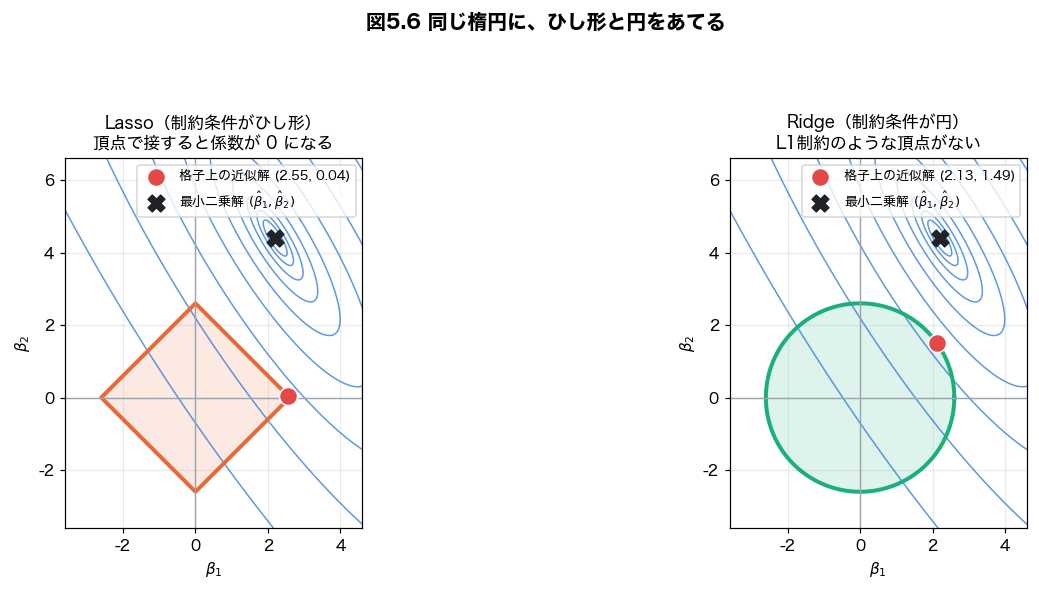

In [8]:
#図5.6 制約領域と等高線
def draw_constraint(ax, kind, beta_hat, Sxx, C, title):
    b1 = np.linspace(-4.0, 5.0, 700); b2 = np.linspace(-4.0, 7.0, 700)
    B1, B2 = np.meshgrid(b1, b2)
    d1, d2 = B1 - beta_hat[0], B2 - beta_hat[1]
    Z = Sxx[0, 0]*d1**2 + 2*Sxx[0, 1]*d1*d2 + Sxx[1, 1]*d2**2
    ax.contour(B1, B2, Z, levels=np.geomspace(0.3, 260, 9),
               colors=[BLUE], linewidths=1.0, alpha=0.75)
    if kind == "lasso":
        t = np.array([[C, 0], [0, C], [-C, 0], [0, -C], [C, 0]])
        ax.plot(t[:, 0], t[:, 1], c=ORANGE, lw=2.6)
        ax.fill(t[:, 0], t[:, 1], color=ORANGE, alpha=0.14)
    else:
        th = np.linspace(0, 2*np.pi, 300)
        ax.plot(C*np.cos(th), C*np.sin(th), c=AQUA, lw=2.6)
        ax.fill(C*np.cos(th), C*np.sin(th), color=AQUA, alpha=0.14)
    #制約のもとでの最小点を数値的に探す
    mask = (np.abs(B1) + np.abs(B2) <= C) if kind == "lasso" else (B1**2 + B2**2 <= C**2)
    Zi = np.where(mask, Z, np.inf)
    i, j = np.unravel_index(np.argmin(Zi), Zi.shape)
    ax.scatter([B1[i, j]], [B2[i, j]], s=140, c=RED, zorder=6, edgecolor="white",
               label=f"格子上の近似解 ({B1[i,j]:.2f}, {B2[i,j]:.2f})")
    ax.scatter(*beta_hat, s=120, marker="X", c="#1F2328", zorder=6,
               label=r"最小二乗解 $(\hat\beta_1,\hat\beta_2)$")
    ax.axhline(0, c="#98a4b0", lw=0.9); ax.axvline(0, c="#98a4b0", lw=0.9)
    ax.set_aspect("equal")                      # 円がつぶれないようにする
    ax.set_xlim(-3.6, 4.6); ax.set_ylim(-3.6, 6.6)
    ax.set_xlabel(r"$\beta_1$"); ax.set_ylabel(r"$\beta_2$")
    ax.set_title(title, fontsize=11); ax.legend(fontsize=8.5, loc="upper right")

beta_hat = np.array([2.2, 4.4])
Sxx = np.array([[9.0, 5.0], [5.0, 4.0]])
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.4))
draw_constraint(axes[0], "lasso", beta_hat, Sxx, 2.6,
                "Lasso（制約条件がひし形）\n頂点で接すると係数が 0 になる")
draw_constraint(axes[1], "ridge", beta_hat, Sxx, 2.6,
                "Ridge（制約条件が円）\nL1制約のような頂点がない")
fig.suptitle("図5.6 同じ楕円に、ひし形と円をあてる", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.90]); plt.show()

---
## 5. $\lambda$ の値の設定（教科書 5.5）

$\lambda$ は罰則の強さを決める**<font color="#E8710A">ハイパーパラメータ</font>**で、通常の回帰係数と同時にこの目的関数だけで決めるものではない。ここではデータを分割して選ぶ。
第 4 回のクロスバリデーションを使い、**<font color="#E8710A">予測誤差が最小になる $\lambda$ を選ぶ</font>**。

10-fold CV であれば、各 $\lambda$ について 9 グループで $\beta$ を推定し、
残り 1 グループでテストする。これを 10 回繰り返して平均の評価値を得る。

---

**<font color="#1A73E8">［補足］「1 標準誤差ルール」</font>**

CV 誤差の曲線は底の付近が平らになることが多く、最小値を与える $\lambda$ は分割の仕方で動きやすい。
そこで**「最小値 ＋ 1 標準誤差」以内で、最も大きい $\lambda$」**を選ぶ流儀がある。
CVの推定誤差の範囲で、より強い正則化を選ぶための経験的なルールである。独立テスト上の性能を保証するものではない。

以下では標準化を各foldの学習部分だけでfitする。Lassoの`alpha=λ`に対し、
RidgeはこのNotebookの目的関数に合わせて`alpha=学習foldの標本数×λ`とする。
分割と二乗誤差の評価基準も両モデルで揃える。

---

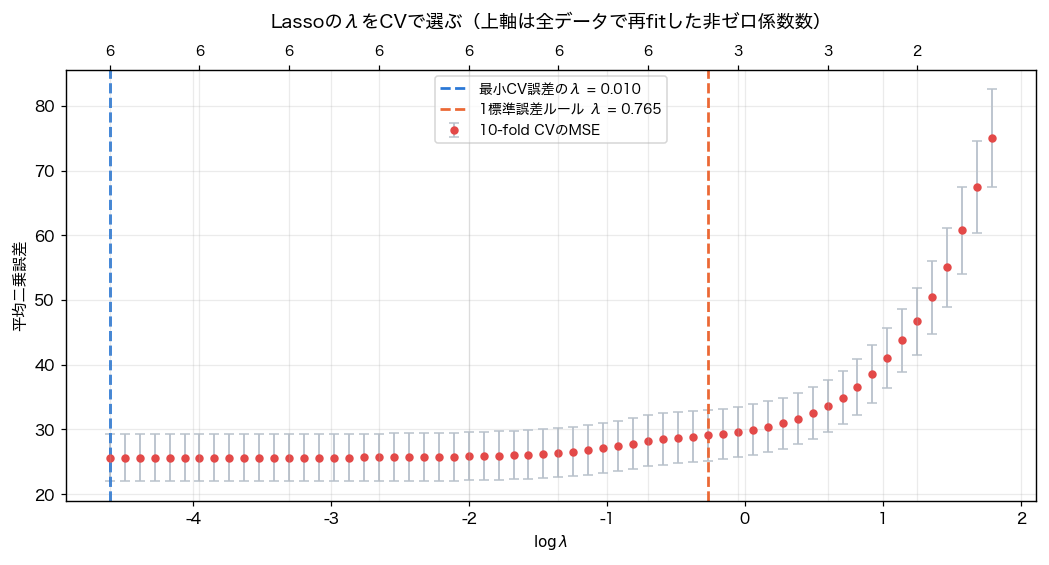

CV最小: λ=0.0100, MSE=25.6086, 非ゼロ=6
1標準誤差: λ=0.7647, MSE=29.0765, 非ゼロ=4
RidgeのCV最小: λ=0.0214, MSE=25.5812
最終fit時のRidge alpha=Nλ: 10.80840680288935
CVで選択した値は候補グリッド内の最小。独立テスト上の誤差ではない。


In [9]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def regularization_cv(X, y, lambdas, seed=0):
    """各学習fold内で標準化し、同じ10分割・MSEで両モデルを比較する。"""
    X, y = np.asarray(X, float), np.asarray(y, float)
    splits = list(KFold(n_splits=10, shuffle=True, random_state=seed).split(X))
    errors_l = np.zeros((len(lambdas), len(splits)))
    errors_r = np.zeros_like(errors_l)
    for fold, (tr, te) in enumerate(splits):
        for i, lam in enumerate(lambdas):
            lm = make_pipeline(StandardScaler(), Lasso(alpha=lam, tol=1e-8, max_iter=50000))
            rm = make_pipeline(StandardScaler(), Ridge(alpha=len(tr)*lam))
            lm.fit(X[tr], y[tr]); rm.fit(X[tr], y[tr])
            errors_l[i, fold] = np.mean((y[te] - lm.predict(X[te]))**2)
            errors_r[i, fold] = np.mean((y[te] - rm.predict(X[te]))**2)
    return dict(lasso_mse=errors_l.mean(1),
                lasso_se=errors_l.std(1, ddof=1)/np.sqrt(len(splits)),
                ridge_mse=errors_r.mean(1),
                fold_train_sizes=[len(tr) for tr, _ in splits])

alphas = np.geomspace(0.01, 6.0, 60)  #この配列は両モデルともNotebookのλ
cv_boston = regularization_cv(Xb, yb, alphas)
mse_mean, mse_se = cv_boston['lasso_mse'], cv_boston['lasso_se']
nnz = np.array([np.count_nonzero(make_pipeline(StandardScaler(),
    Lasso(alpha=a, tol=1e-8, max_iter=50000)).fit(Xb, yb).named_steps['lasso'].coef_)
    for a in alphas])
i_min = int(np.argmin(mse_mean))
thresh = mse_mean[i_min] + mse_se[i_min]
i_1se = int(np.max(np.flatnonzero(mse_mean <= thresh)))
i_ridge = int(np.argmin(cv_boston['ridge_mse']))

fig, ax = plt.subplots(figsize=(9.6, 5.2))
ax.errorbar(np.log(alphas), mse_mean, yerr=mse_se, fmt='o', ms=4.5, color=RED,
            ecolor='#b9c2cc', elinewidth=1.2, capsize=3, label='10-fold CVのMSE')
ax.axvline(np.log(alphas[i_min]), c=BLUE, ls='--', lw=1.8,
           label=rf'最小CV誤差のλ = {alphas[i_min]:.3f}')
ax.axvline(np.log(alphas[i_1se]), c=ORANGE, ls='--', lw=1.8,
           label=rf'1標準誤差ルール λ = {alphas[i_1se]:.3f}')
ax.set_xlabel(r'$\log\lambda$'); ax.set_ylabel('平均二乗誤差')
ax.set_title('LassoのλをCVで選ぶ（上軸は全データで再fitした非ゼロ係数数）', pad=28)
axt = ax.twiny(); axt.set_xlim(ax.get_xlim())
sel = np.arange(0, len(alphas), 6)
axt.set_xticks(np.log(alphas)[sel]); axt.set_xticklabels(nnz[sel], fontsize=9)
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
print(f'CV最小: λ={alphas[i_min]:.4f}, MSE={mse_mean[i_min]:.4f}, 非ゼロ={nnz[i_min]}')
print(f'1標準誤差: λ={alphas[i_1se]:.4f}, MSE={mse_mean[i_1se]:.4f}, 非ゼロ={nnz[i_1se]}')
print(f'RidgeのCV最小: λ={alphas[i_ridge]:.4f}, MSE={cv_boston["ridge_mse"][i_ridge]:.4f}')
print('最終fit時のRidge alpha=Nλ:', len(yb)*alphas[i_ridge])
print('CVで選択した値は候補グリッド内の最小。独立テスト上の誤差ではない。')


---
## 6. 教科書の章末問題（問題 49〜56）への取り組み方

| 問題 | 内容 | この回のどこを見るか |
| --- | --- | --- |
| 49 | $N<p$ のとき解が存在すること、$\lambda>0$ との同値性 | 第 1 節 |
| 50 | 劣微分の定義、$\|x\|$ の劣微分、極値の判定 | 第 2 節 |
| 51 | `soft_th` の実装と作図 | 第 3 節 |
| 52 | 直交する場合の Lasso 解 $\mathcal{S}_\lambda(z)$ | 第 3 節 3.2 |
| 53 | 座標降下法による `lasso` の空欄うめ | 第 3 節 3.3 |
| 54 | 同じ処理を Ridge に書き換える | 第 1 節の `ridge` |
| 55 | `Lasso` / `LassoCV` の意味と最適な $\lambda$ | 第 5 節 |
| 56 | (5.6) の導出、ひし形と円の接点 | 第 4 節 |

---

**<font color="#7B3FB5">［演習］原問に取り組むときの確認点</font>**

**問題 49**：「必要十分の関係になる」ので両方向の証明が必要。
$\Leftarrow$ は本文の 3 段論法。$\Rightarrow$ は $\lambda=0$ かつ $N<p$ で解が一意でないことを示す。

**問題 50(c)**：$x_0>0$、$x_0<0$、$x_0=0$ の 3 通りに分ける。
$x_0\neq0$ では微分可能なので劣微分は 1 点集合。

**問題 51**：ヒントにあるとおり `max` ではなく `np.maximum` を使う。
前者は 2 つのスカラーの比較で、配列には使えない。

**問題 53**：空欄 (1) は $r$ の計算、(2) は `soft_th` の呼び出し、(3) は切片。
更新した `beta[j]` をその場で次に使う点に注意。

**問題 54**：`while` ループを 中心化・標準化後に `np.linalg.solve(X.T@X+n*lam*np.eye(p), X.T@y)`
で直接解く方法に置き換えられる。切片の復元とλの規約も揃える。

**問題 56(b)**：正方形（ひし形）の 4 頂点 $(1,0),(0,1),(-1,0),(0,-1)$ を結ぶ図を描き、
円の半径を大きくしていったときの接点の軌跡を考える。

---

### 演習（提出用）

---

**<font color="#7B3FB5">［演習］演習 6-1　ソフト閾値から Lasso 解を導く</font>**

$p=1$、標準化済み（$\frac1N\sum_ix_i^2=1$）とする。

(a) $L=\frac{1}{2N}\sum_i(y_i-x_i\beta)^2+\lambda|\beta|$ の $\beta$ に関する劣微分を書き下せ。

(b) $\beta>0,\ \beta<0,\ \beta=0$ に場合分けして、解が $\mathcal{S}_\lambda(s)$ になることを示せ。

(c) $s=0.8,\ \lambda=0.3$ のとき、$L(\beta)$ を $\beta\in[-1,1]$ で数値的に描き、
最小点が $\mathcal{S}_{0.3}(0.8)=0.5$ になることを確かめよ。

---

---

**<font color="#7B3FB5">［演習］演習 6-2　Ridge と Lasso の予測性能を比べる</font>**

$N=80,\ p=60$ で、真の係数のうち**5 個だけ**が非ゼロ（スパース）の人工データを作る。

(a) Ridge と Lasso それぞれについて、10-fold CV で候補内の $\lambda$ を選べ。標準化は学習fold内で行う。

(b) 別に生成したテストデータで二乗誤差を比べよ。

(c) 真の非ゼロ変数を Lasso が何個選べたか（再現率）、
余計に選んだ変数が何個か（誤選択）を数えよ。

(d) 今度は真の係数を**すべて小さな値で非ゼロ**にして (a)(b) を繰り返し、
どちらが有利になるか確かめよ。

---

---

**<font color="#7B3FB5">［演習］演習 6-3　標準化を忘れるとどうなるか</font>**

Boston の 6 変数について、標準化**せずに** Lasso を当て、
標準化した場合と係数パスを比べよ。

(a) どの変数が不当に残り、どの変数が不当に消えるか。

(b) その理由を、各変数の標準偏差の大きさと結びつけて説明せよ。

---

=== 演習 6-1 ===
  数値的な最小点 : 0.5000
  S_λ(s)         : 0.5000


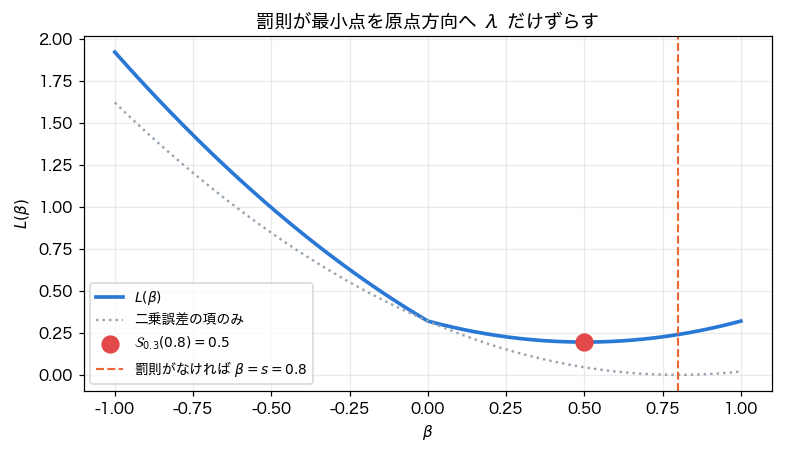


=== 演習 6-2 ===
  (a) Lasso の λ = 0.1202   Ridge の λ = 0.0322
  (b) テスト二乗誤差  Lasso 1.2214   Ridge 5.3252
  (c) 真の非ゼロ 5 個中 5 個を選択、余計に 10 個
  (d) すべて非ゼロの場合  Lasso 2.3399   Ridge 2.6258
      これは1つのseedと探索範囲での比較。疎・密という構造だけで優劣は保証されない。

=== 演習 6-3 ===


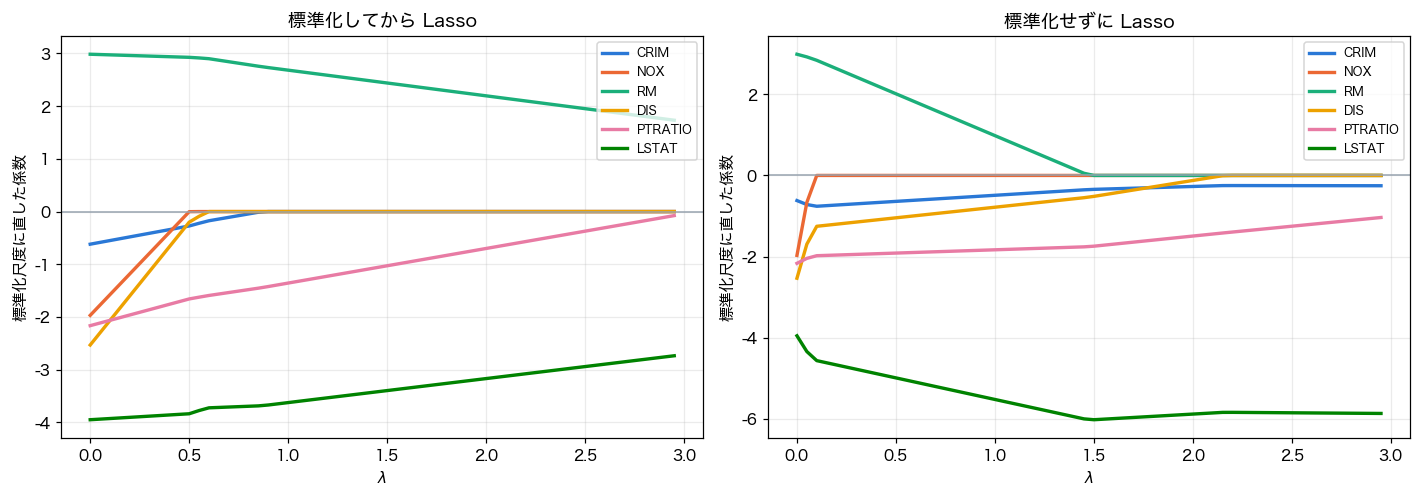

  各変数の標準偏差: {'CRIM': 8.593, 'NOX': 0.116, 'RM': 0.702, 'DIS': 2.104, 'PTRATIO': 2.163, 'LSTAT': 7.134}
  (a)(b) 標準偏差はNOXが約0.12、PTRATIOが約2.16、CRIMが約8.59と異なるため、
        同じ罰則でも縮み方が変わる。標準偏差が小さい変数ほど係数が大きく出るので、
        標準化しないと「単位の選び方」が変数選択を左右してしまう。


In [10]:
#解答と確認用の実装（まず自分で解いてから実行すること）
print("=== 演習 6-1 ===")
s_val, lam_val = 0.8, 0.3
bg = np.linspace(-1, 1, 2001)
Lb = 0.5*(bg - s_val)**2 + lam_val*np.abs(bg)      # 定数項を除いた L
print(f"  数値的な最小点 : {bg[int(np.argmin(Lb))]:.4f}")
print(f"  S_λ(s)         : {soft_th(lam_val, s_val):.4f}")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(bg, Lb, c=BLUE, lw=2.4, label=r"$L(\beta)$")
ax.plot(bg, 0.5*(bg - s_val)**2, c="#98a4b0", lw=1.6, ls=":", label="二乗誤差の項のみ")
ax.scatter([soft_th(lam_val, s_val)], [Lb[int(np.argmin(Lb))]], s=120, c=RED, zorder=5,
           label=r"$\mathcal{S}_{0.3}(0.8)=0.5$")
ax.axvline(s_val, c=ORANGE, ls="--", lw=1.4, label=r"罰則がなければ $\beta=s=0.8$")
ax.set_xlabel(r"$\beta$"); ax.set_ylabel(r"$L(\beta)$")
ax.set_title("罰則が最小点を原点方向へ λ だけずらす"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print("\n=== 演習 6-2 ===")
def sparse_experiment(sparse=True, N=80, p=60, n_nz=5, seed=3):
    rg2 = np.random.default_rng(seed)
    bt = np.zeros(p)
    if sparse:
        bt[:n_nz] = rg2.normal(0, 2.5, n_nz)
    else:
        bt[:] = rg2.normal(0, 0.35, p)
    Xtr = rg2.standard_normal((N, p)); ytr = Xtr @ bt + rg2.standard_normal(N)
    Xte = rg2.standard_normal((400, p)); yte = Xte @ bt + rg2.standard_normal(400)
    al = np.geomspace(0.01, 3.0, 40)
    cv_result = regularization_cv(Xtr, ytr, al, seed=0)
    il = int(np.argmin(cv_result['lasso_mse']))
    ir = int(np.argmin(cv_result['ridge_mse']))
    lc = make_pipeline(StandardScaler(), Lasso(alpha=al[il], tol=1e-8, max_iter=50000)).fit(Xtr, ytr)
    rc = make_pipeline(StandardScaler(), Ridge(alpha=N*al[ir])).fit(Xtr, ytr)
    mse_l = np.mean((yte - lc.predict(Xte))**2)
    mse_r = np.mean((yte - rc.predict(Xte))**2)
    sel = np.flatnonzero(lc.named_steps['lasso'].coef_ != 0)
    true_nz = np.flatnonzero(bt != 0)
    return dict(lam_l=float(al[il]), lam_r=float(al[ir]), alpha_r=float(N*al[ir]), mse_l=float(mse_l), mse_r=float(mse_r),
                hit=len(set(sel) & set(true_nz)), extra=len(set(sel) - set(true_nz)),
                n_true=len(true_nz))

r_sp = sparse_experiment(True)
print(f"  (a) Lasso の λ = {r_sp['lam_l']:.4f}   Ridge の λ = {r_sp['lam_r']:.4f}")
print(f"  (b) テスト二乗誤差  Lasso {r_sp['mse_l']:.4f}   Ridge {r_sp['mse_r']:.4f}")
print(f"  (c) 真の非ゼロ {r_sp['n_true']} 個中 {r_sp['hit']} 個を選択、"
      f"余計に {r_sp['extra']} 個")
r_dn = sparse_experiment(False)
print(f"  (d) すべて非ゼロの場合  Lasso {r_dn['mse_l']:.4f}   "
      f"Ridge {r_dn['mse_r']:.4f}")
print("      これは1つのseedと探索範囲での比較。疎・密という構造だけで優劣は保証されない。")

print("\n=== 演習 6-3 ===")
lam_g = np.arange(0, 3.0, 0.05)
raw = np.array([lasso(Xb, yb, l)["beta"] for l in lam_g])          # 標準化あり（自作関数の中で）
#標準化なしの座標降下法
def lasso_nostd(X, y, lam, tol=1e-5, max_iter=800):
    n, p = X.shape
    yc = y - y.mean(); Xc = X - X.mean(0)
    beta = np.zeros(p); old = np.ones(p); it = 0
    while np.max(np.abs(beta-old)) > tol and it < max_iter:
        old = beta.copy()
        for j in range(p):
            idx = [k for k in range(p) if k != j]
            r = yc - Xc[:, idx] @ beta[idx]
            beta[j] = soft_th(lam, Xc[:, j] @ r / n) / (Xc[:, j] @ Xc[:, j] / n)
        it += 1
    return beta
nostd = np.array([lasso_nostd(Xb, yb, l) for l in lam_g])

fig, axs = plt.subplots(1, 2, figsize=(13.0, 4.6))
for j, (lab, c) in enumerate(zip(labels, PAL)):
    axs[0].plot(lam_g, raw[:, j] * Xb.std(0)[j], color=c, lw=2.2, label=lab)
    axs[1].plot(lam_g, nostd[:, j] * Xb.std(0)[j], color=c, lw=2.2, label=lab)
axs[0].set_title("標準化してから Lasso"); axs[1].set_title("標準化せずに Lasso")
for a in axs:
    a.axhline(0, c="#98a4b0", lw=1.0); a.set_xlabel(r"$\lambda$")
    a.set_ylabel("標準化尺度に直した係数"); a.legend(fontsize=8)
fig.tight_layout(); plt.show()
print("  各変数の標準偏差:", {l: round(float(v), 3) for l, v in zip(labels, Xb.std(0))})
print("  (a)(b) 標準偏差はNOXが約0.12、PTRATIOが約2.16、CRIMが約8.59と異なるため、")
print("        同じ罰則でも縮み方が変わる。標準偏差が小さい変数ほど係数が大きく出るので、")
print("        標準化しないと「単位の選び方」が変数選択を左右してしまう。")

---
## 7. この回のまとめ

|  | Ridge | Lasso |
| --- | --- | --- |
| 罰則 | $\lambda\Vert \beta\Vert _2^2$ | $\lambda\Vert \beta\Vert _1$ |
| 制約領域 | 円（なめらか） | ひし形（頂点あり） |
| 解 | $(X^TX+N\lambda I)^{-1}X^Ty$（閉じた形） | 一般には座標降下法で反復。直交時はソフト閾値 |
| 係数が 0 になるか | ソフト閾値のように0へ切り落とす機構はない。特殊な条件では0にもなる | **なる**（変数選択の役割） |
| 原点での微分 | 可能 | 不可能。劣微分は $[-1,1]$ |
| 得意な場面 | 全変数が少しずつ効く／共線形性が強い | 真の構造がスパース |
| $N<p$ | $\lambda>0$ なら係数解は一意 | 最適解は得られるが係数は一意とは限らない |

---

**<font color="#E8710A">［要点］次回への橋渡し</font>**

ここまでの 6 回は、$y$ が $x$ の**線形結合**で書けるという前提の上にあった。
Ridge も Lasso も、その線形結合の係数を縮めているにすぎない。

第 7 回からは、この前提を外す。$x$ を $f_1(x),\dots,f_p(x)$ という基底関数に置き換えれば、
**係数についてはあいかわらず線形**のまま、$x$ について非線形な関係を表せる。
多項式回帰とスプライン回帰は、その基底の選び方の違いである。

---

## 参考資料と検証の範囲
鈴木讓 著『統計的機械学習の数理100問 with Python』共立出版、2020年。第5章「正則化」を中心とした学習記録です。
[出版社](https://www.kyoritsu-pub.co.jp/book/b10003244.html) / [Lassoの目的関数](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) / [Ridgeの目的関数](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) / [データ漏洩を避ける前処理](https://scikit-learn.org/stable/common_pitfalls.html)

CVは前処理を各学習foldでfitする形に修正しました。人工データのテスト400点はCVとは別に生成しています。
単一seedと有限のλグリッドによる実験であり、Ridge/Lassoの一般的な優劣を示すものではありません。
